In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold, cross_val_predict, cross_validate
from sklearn.linear_model import LinearRegression
from scipy.stats import gaussian_kde

sys.path.insert(1, '../../ProcessEvents')
from config import CATCHMENT_LOOKUP_DICT, ENSEMBLE_MEMBERS, CATCHMENTS

from PrepDataFunctions import *

### Get event data

In [28]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl", 
                        remove_events_with_zero_flooding = False)
# df[df['max_quartile_index_n'].isnull()][["max_precip", "max_quartile_index_n", "length", "total_acc", "length_of_active_rain"]]
# df = create_subset(df, 10000, 10)
subset_early = create_temporal_subset(df, "before", 2020)

In [29]:
subset_early = subset_early[subset_early['y_coord'] < 560000]

In [31]:
# THRESH = 100

# XCOL, YCOL = "x_coord", "y_coord"                        # <- change; if coords live in df: coords = df.loc[X.index, [XCOL, YCOL]]
# coords = subset_early.loc[subset_early.index, [XCOL, YCOL]]
# xy = coords.values

# low_ids = y.index[y < 0.1]
# flag = subset_early.index.isin(low_ids)
# fig, ax = plt.subplots(1, 3, figsize=(10, 4.5))
# ax[0].scatter(xy[~flag, 0], xy[~flag, 1], s=2, c="lightgrey")
# ax[0].scatter(xy[flag, 0], xy[flag, 1], s=4, c="crimson"); ax[0].set_title("Low-response pixels (red)")

### Create version of model with all variables included

In [32]:
rf = RandomForestRegressor(n_estimators=800, min_samples_leaf = 2, max_depth=16,max_samples = None, max_features = 1.0, 
                           random_state=42)
lr = LinearRegression()
cv_parameters = KFold(n_splits=5, shuffle=True, random_state=42)
error_metrics = ['neg_mean_absolute_error', 'r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_percentage_error']

In [33]:
predictor_variables = [col for col in subset_early.columns if col not in ['10cm_area', '10cm_volume', '30cm_area', '30cm_volume']]

# Define X (predictors) and Y (response)
X = subset_early[predictor_variables]
y = subset_early['10cm_area']

In [35]:
len(subset_early)

17984

In [34]:
y_pred_lr = cross_val_predict(lr, X, y, cv=cv_parameters)
y_pred_rf = cross_val_predict(rf, X, y, cv=cv_parameters)


KeyboardInterrupt



In [ ]:
# all_variables_r2_lr = cross_val_score(lr, X, y, cv=cv_parameters, scoring='r2').mean()
# print(f"Full model R²: {all_variables_r2_lr:.4f}")

# all_variables_r2_rf = cross_val_score(rf, X, y, cv=cv_parameters, scoring='r2').mean()
# print(f"Full model R²: {all_variables_r2_rf:.4f}")

In [36]:
all_variables_r2_lr = cross_val_score(lr, X, y, cv=cv_parameters, scoring='r2').mean()
print(f"Full model R²: {all_variables_r2_lr:.4f}")

all_variables_r2_rf = cross_val_score(rf, X, y, cv=cv_parameters, scoring='r2').mean()
print(f"Full model R²: {all_variables_r2_rf:.4f}")

Full model R²: 0.5916
Full model R²: 0.8402


In [ ]:
# # Use cross_validate to return the error scores associated with this model and this data
# model_output = cross_validate(rf, X, y, cv=cv_parameters, scoring=error_metrics, error_score="raise")

# # Formulate the different error scores into a dataframe
# error_metrics_df =pd.DataFrame({'mae': round(abs(model_output['test_neg_mean_absolute_error'].mean()),2), 
#               'mape': round(abs(model_output['test_neg_mean_absolute_percentage_error'].mean()),2),
#               'r2': round(abs(model_output['test_r2'].mean()),2), 
#               'rmse': round(abs(model_output['test_neg_root_mean_squared_error'].mean()),2)}, index =["RF"])

# error_metrics_df

NameError: name 'y_pred_rf' is not defined

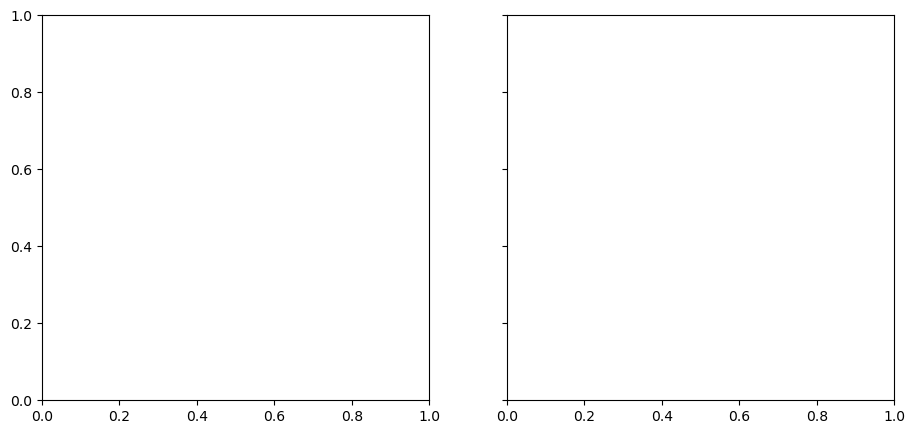

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)

for ax, y_pred, name, r2 in zip(axes,
    [y_pred_lr, y_pred_rf],
    ['Linear regression', 'Random forest'],[all_variables_r2_lr, all_variables_r2_rf]):
    xy = np.vstack([y,y_pred])
    z = gaussian_kde(xy)(xy)
    ax.scatter(y, y_pred, alpha=0.9, s=15, c = z, edgecolor='none')
    
    # using_datashader(axs[0], y, y_pred, 'linear')
    
    # 1:1 reference line
    lims = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
    ax.plot(lims, lims, 'k--', linewidth=1, label='1:1')
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    
    ax.set_xlabel('Observed 10cm_area')
    ax.set_ylabel('Predicted 10cm_area')
    ax.set_title(f'{name}\nR² = {r2:.3f}')
    ax.set_aspect('equal')
    ax.legend()

plt.tight_layout()
plt.show()

## Using SHAP

In [38]:
import shap 
rf.fit(X,y)
explainer = shap.TreeExplainer(rf)

In [ ]:
shap_values = explainer.shap_values(X)

# Global summary: which variables matter most overall, and in which direction
shap.summary_plot(shap_values, X, show=True, max_display=70)

In [ ]:
# Source - https://stackoverflow.com/a/70479829
# Posted by mozway
# Retrieved 2026-10-06, License - CC BY-SA 4.0

# subset.corrwith(subset['peak_cell_inside_prop'])[:50]